#  Model A — Ensemble Learning
### Intelligent Reading Comprehension System

## 1.  Import Libraries

In [4]:
import os
import time
import warnings

import pandas as pd
import numpy as np
import scipy.sparse as sparse

from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings("ignore")

## 2.  Load Datasets & Features

In [5]:
train_df = pd.read_csv('../data/processed/binary_train.csv')
test_df  = pd.read_csv('../data/processed/binary_test.csv')

y_train = train_df['label']
y_test  = test_df['label']

X_train = sparse.load_npz('../data/processed/X_train_tfidf.npz')
X_test  = sparse.load_npz('../data/processed/X_test_tfidf.npz')

print(f"Train : {X_train.shape}")
print(f"Test  : {X_test.shape}")

Train : (281168, 5000)
Test  : (35148, 5000)


## 3.  Load Pre-Trained Base Models


In [6]:
log_reg     = joblib.load('../models/traditional/model_a_logistic_regression.pkl')
naive_bayes = joblib.load('../models/traditional/model_a_naive_bayes.pkl')

print("Base models loaded ✓")

Base models loaded ✓


## 4.  Build & Train Soft Voting Ensemble


In [7]:
ensemble_model = VotingClassifier(
    estimators=[('lr', log_reg), ('nb', naive_bayes)],
    voting='soft'
)

start = time.time()
ensemble_model.fit(X_train, y_train)
elapsed = time.time() - start

print(f"Ensemble trained in {elapsed:.2f} seconds ✓")

Ensemble trained in 29.63 seconds ✓


## 5.  Generate Predictions

In [8]:
ensemble_preds = ensemble_model.predict(X_test)

## 6. Evaluate Performance

In [9]:
metrics = {
    'Accuracy':    accuracy_score(y_test, ensemble_preds),
    'Precision':   precision_score(y_test, ensemble_preds, average='macro'),
    'Recall':      recall_score(y_test, ensemble_preds, average='macro'),
    'Macro F1':    f1_score(y_test, ensemble_preds, average='macro'),
    'Exact Match': np.mean(ensemble_preds == y_test),
    'Training Time (sec)': elapsed
}

for k, v in metrics.items():
    print(f"  {k:<22}: {v:.4f}")

  Accuracy              : 0.5100
  Precision             : 0.5069
  Recall                : 0.5092
  Macro F1              : 0.4756
  Exact Match           : 0.5100
  Training Time (sec)   : 29.6294


In [10]:
print(classification_report(y_test, ensemble_preds))

              precision    recall  f1-score   support

           0       0.76      0.51      0.61     26361
           1       0.26      0.51      0.34      8787

    accuracy                           0.51     35148
   macro avg       0.51      0.51      0.48     35148
weighted avg       0.63      0.51      0.54     35148



## 7.  Confusion Matrix

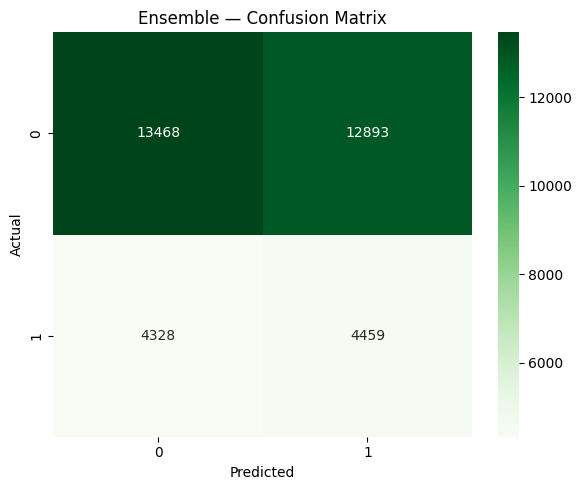

In [11]:
cm = confusion_matrix(y_test, ensemble_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title('Ensemble — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/ensemble_confusion_matrix.png', dpi=150, bbox_inches='tight')

plt.tight_layout()
plt.show()

## 8.  Save Results & Model

In [12]:
os.makedirs('../reports', exist_ok=True)
os.makedirs('../models/ensemble', exist_ok=True)

# Results CSV
results_df = pd.DataFrame(metrics.items(), columns=['Metric', 'Value'])
results_df.to_csv('../reports/model_c_ensemble_results.csv', index=False)

# Trained ensemble
joblib.dump(ensemble_model, '../models/ensemble/soft_voting_ensemble.pkl')

print("Artifacts saved:")
print("  ../reports/model_c_ensemble_results.csv")
print("  ../reports/figures/ensemble_confusion_matrix.png")
print("  ../models/ensemble/soft_voting_ensemble.pkl")

Artifacts saved:
  ../reports/model_c_ensemble_results.csv
  ../reports/figures/ensemble_confusion_matrix.png
  ../models/ensemble/soft_voting_ensemble.pkl
